# Stroke prediction analysis 

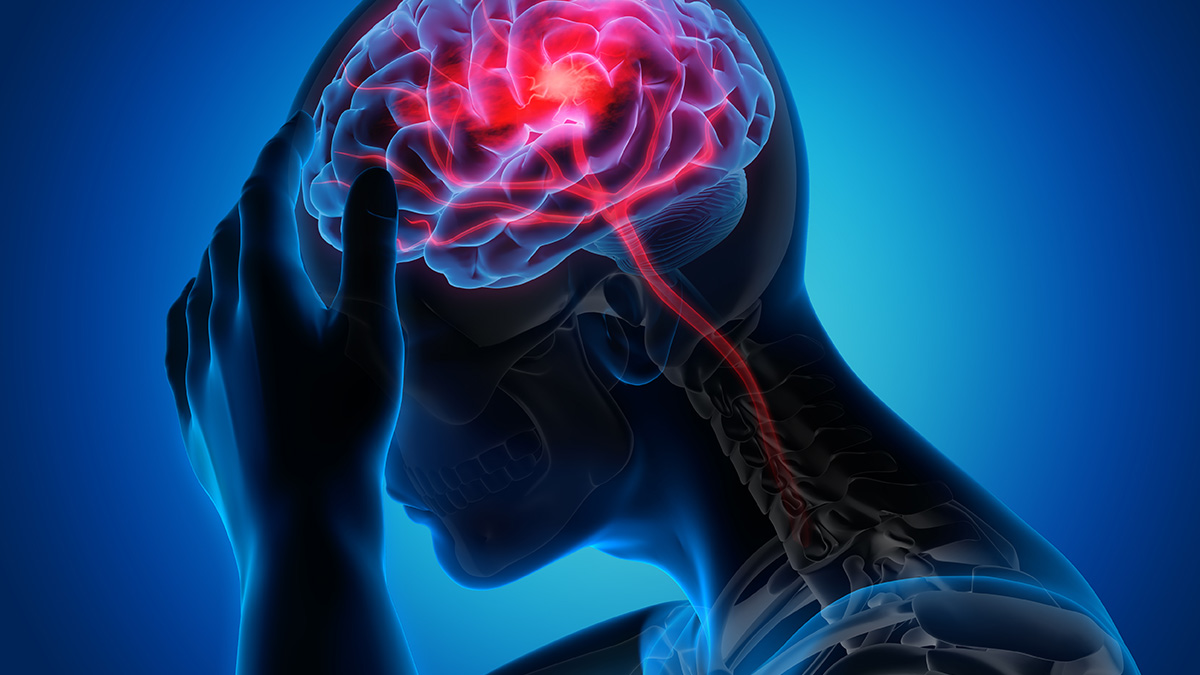
## Project Objective

The goal of this project is to predict whether a patient is likely to have a stroke based on their medical and demographic features using machine learning.

### Key Questions
- Which factors are associated with a higher stroke risk in adults?
- Is stroke more common in males or females?
- Can children also experience a stroke?


### importing nessesary libriaries 

In [95]:
import pandas as pd 
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score, precision_score


In [75]:
strokedf=pd.read_csv("../data/raw.csv")

In [5]:
strokedf

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
...,...,...,...,...,...,...,...,...,...,...,...,...
5105,18234,Female,80.0,1,0,Yes,Private,Urban,83.75,NaN,never smoked,0
5106,44873,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.0,never smoked,0
5107,19723,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.6,never smoked,0
5108,37544,Male,51.0,0,0,Yes,Private,Rural,166.29,25.6,formerly smoked,0


## The dataset used in this project contains medical records of patients and their associated risk factors for stroke

| Feature | Description |
|---|---|
| Id | Unique identification number for each patient |
| Age | Age of the patient |
| Hypertension | Whether the patient has hypertension (1 = yes, 0 = no) |
| Heart Disease | Whether the patient has a history of heart disease (1 = yes, 0 = no) |
| Ever Married | Whether the patient has been married (1 = yes, 0 = no) |
| Work Type | Type of work the patient does, such as private, self-employed, government, or children |
| Residence Type | Whether the patient lives in an urban or rural area |
| Glucose Level | The patient's average glucose level |
| BMI | Body Mass Index, a measure of body fat based on height and weight |
| Smoking Status | The patient's smoking habit, such as never smoked, formerly smoked, or currently smoking |
| Stroke | Target variable indicating whether the patient had a stroke (1 = yes, 0 = no) |


## Data exploration

In [76]:
strokedf.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [77]:
strokedf.tail()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
5105,18234,Female,80.0,1,0,Yes,Private,Urban,83.75,NaN,never smoked,0
5106,44873,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.0,never smoked,0
5107,19723,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.6,never smoked,0
5108,37544,Male,51.0,0,0,Yes,Private,Rural,166.29,25.6,formerly smoked,0
5109,44679,Female,44.0,0,0,Yes,Govt_job,Urban,85.28,26.2,Unknown,0


data is sorted by stroke, we need to shuffle it before splitting it into train and test sets 

In [6]:
strokedf.isnull().sum()


id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

In [7]:
strokedf.shape

(5110, 12)

In [8]:
strokedf.info()


<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


In [9]:
strokedf.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


# Insights

Insights:Target Variable (stroke):

- The mean value is 0.0487, indicating that only about 4.87% of the patients in the dataset had a stroke. This shows class imbalance, which might require handling during model :)

- Most patients do not have heart disease , hypertension

- dataset have an adults and childerns 

- there are many values for age = 0 and outliers in average glucose level 

Average Glucose Level in Blood

- Mean: 106.15 around the normal range for fasting glucose levels

- Std: 45.28 (high variability, with potential outliers).

- Min: 55.12  normal range

- Max: 271.74  very high, likely diabetic levels

- Patients with high glucose levels may correlate with stroke risk, which should be explored further


- Outliers in BMI values might need to be handled +201 MISSING VALUES

## Outlier detection

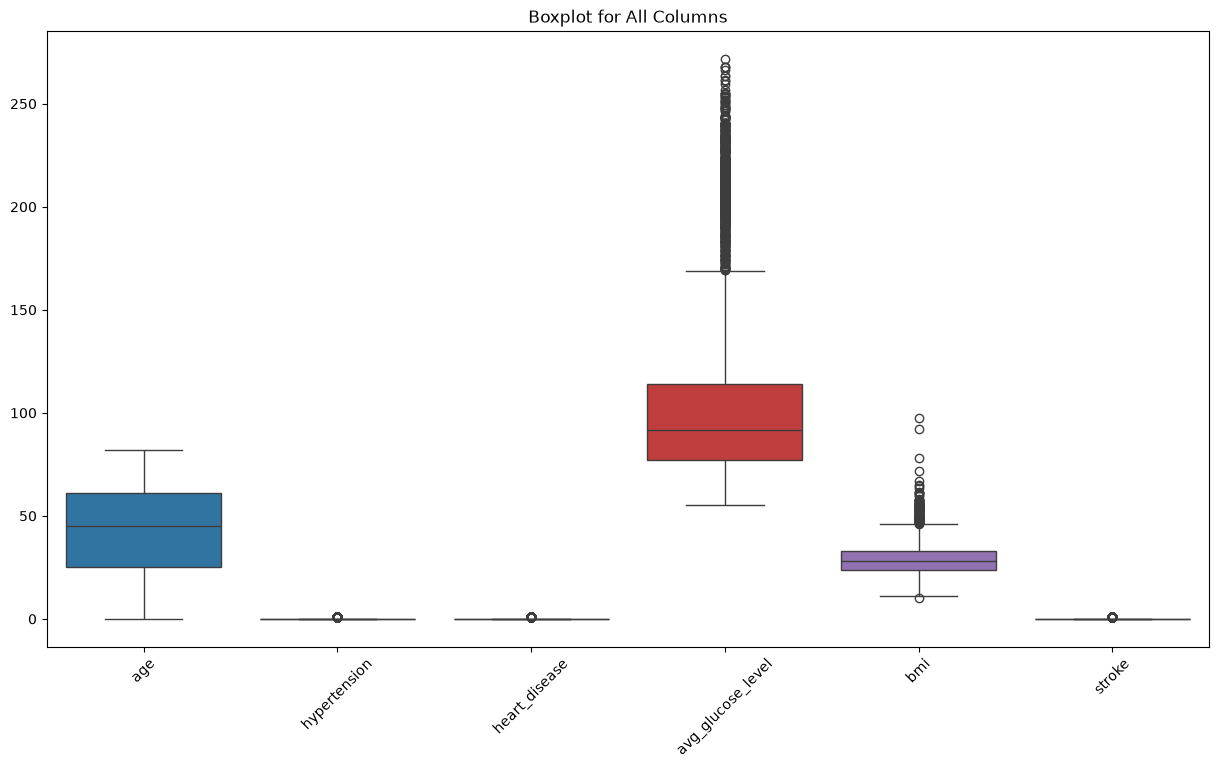

In [ ]:
#Boxplot
plt.figure(figsize=(15, 8))
sns.boxplot(data=strokedf)
plt.xticks(rotation=45)  
plt.title("Boxplot for All Columns")
plt.show()

## Explory data analysis (EDA )

array([[<Axes: title={'center': 'age'}>,
        <Axes: title={'center': 'hypertension'}>],
       [<Axes: title={'center': 'heart_disease'}>,
        <Axes: title={'center': 'avg_glucose_level'}>],
       [<Axes: title={'center': 'bmi'}>,
        <Axes: title={'center': 'stroke'}>]], dtype=object)

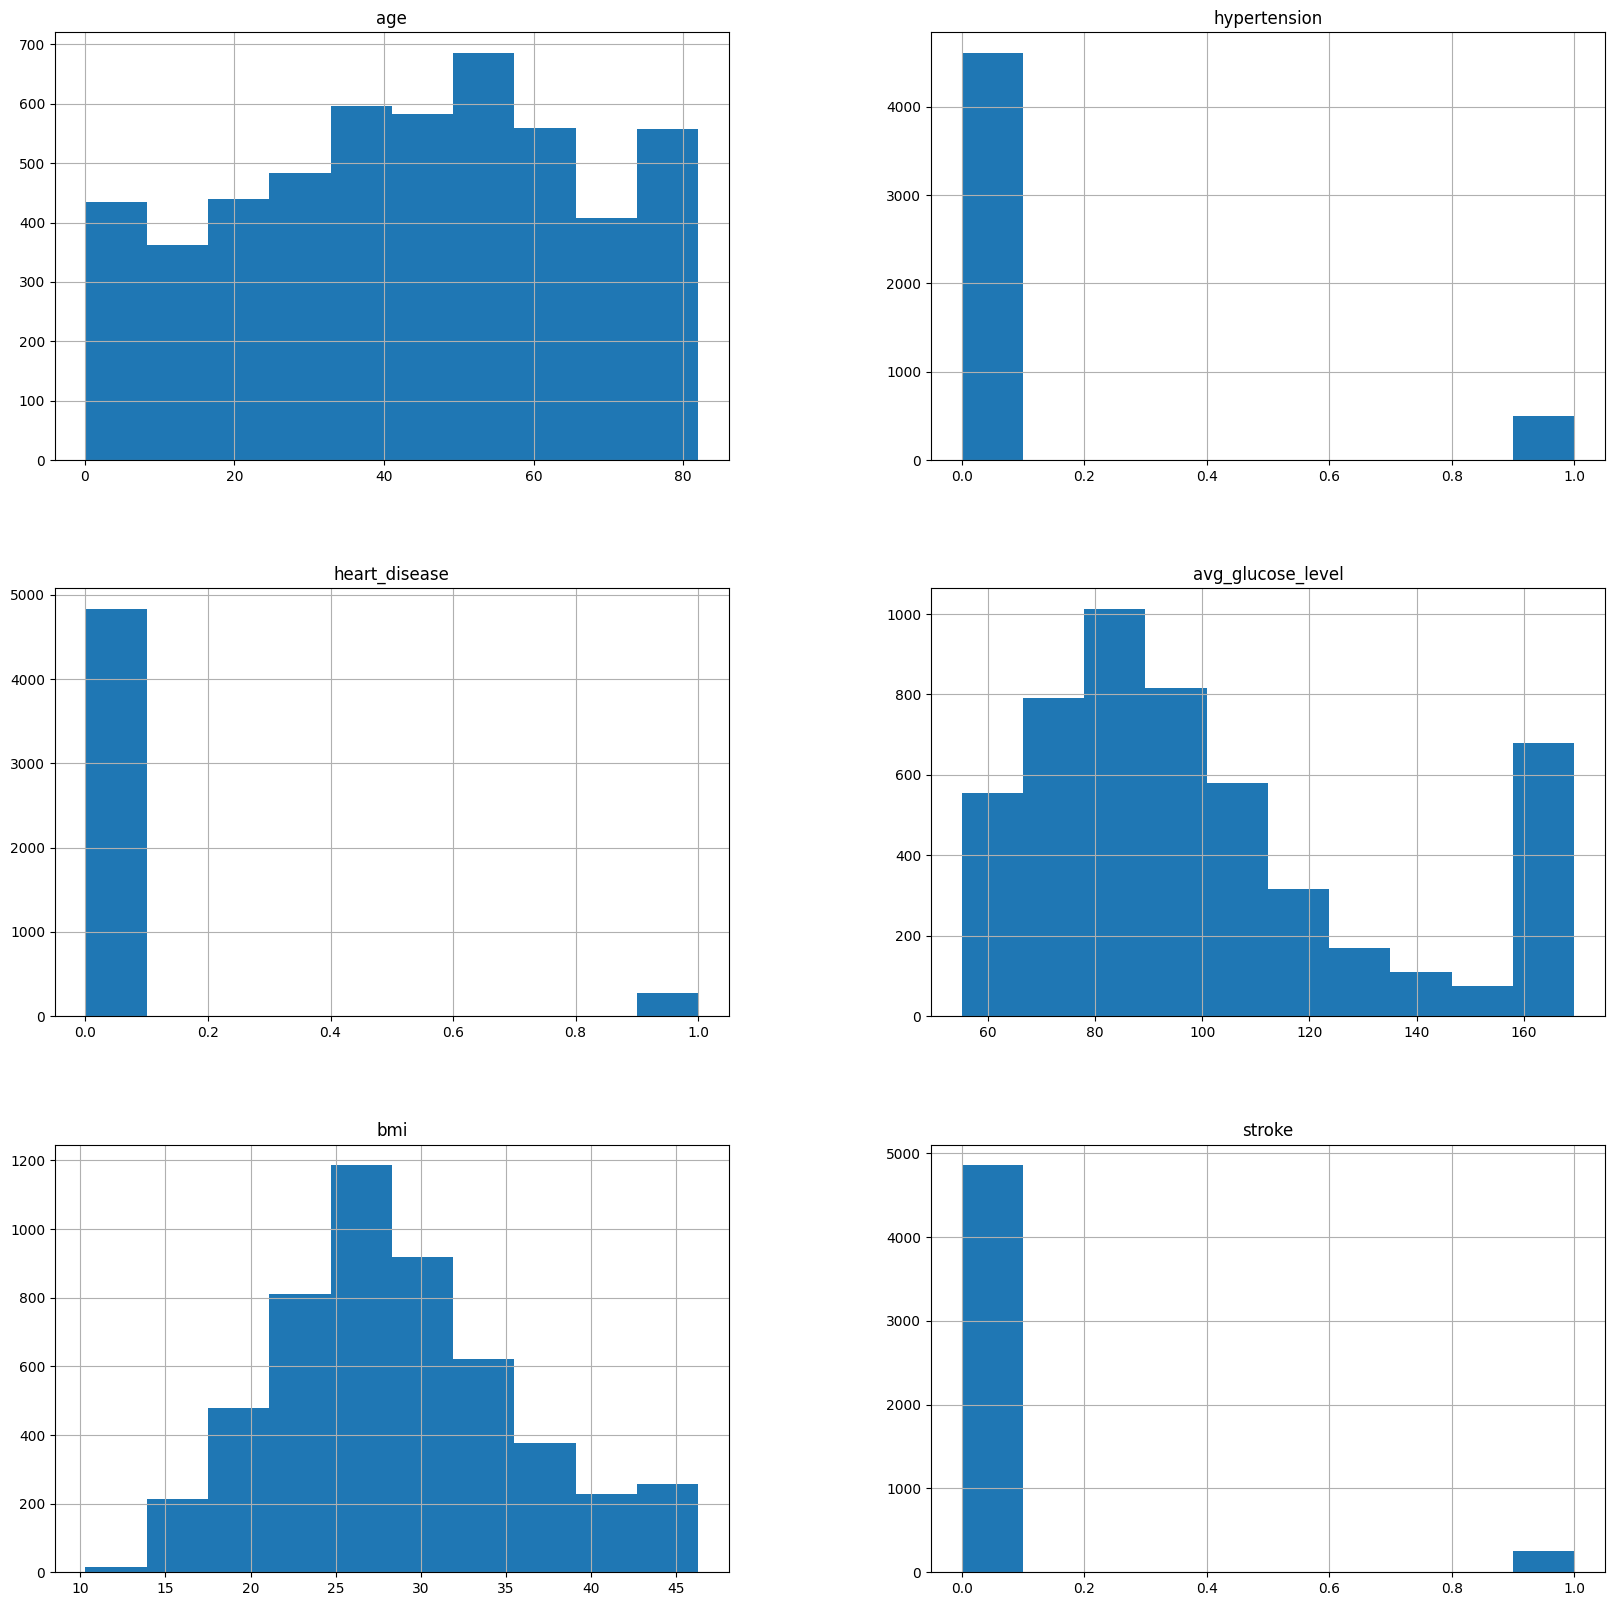

In [107]:
strokedf.hist(figsize=(20,20))

# Gender analysis

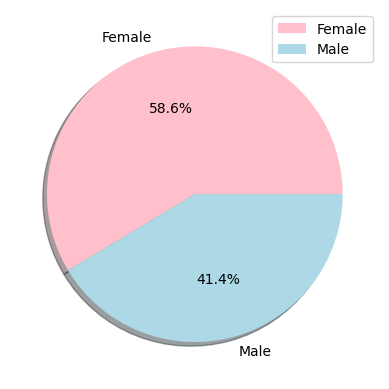

In [108]:
plt.pie(strokedf['gender'].value_counts(),labels=['Female','Male'],colors=['pink','lightblue'],autopct='%1.1f%%',shadow=True)
plt.legend()
plt.show()

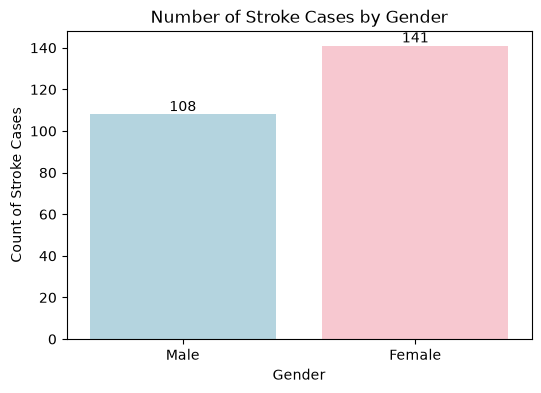

In [15]:
# bar chart: number of males and females who had a stroke
stroke_gender = strokedf[strokedf['stroke'] == 1]
plt.figure(figsize=(6,4))
ax = sns.countplot(x='gender', data=stroke_gender, palette=['lightblue','pink'])
ax.set_title('Number of Stroke Cases by Gender')
ax.set_xlabel('Gender')
ax.set_ylabel('Count of Stroke Cases')
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom')
plt.show()

females get stroke more than males !!!

# Gender vs Smoking

<Axes: xlabel='gender', ylabel='count'>

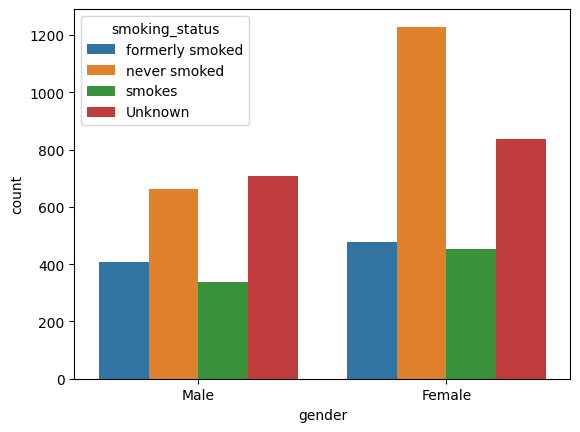

In [109]:
#Some visualization
sns.countplot(data=strokedf,x='gender',hue='smoking_status')


mostly woman is less trends towards smoking



# Heart disaese vs gender

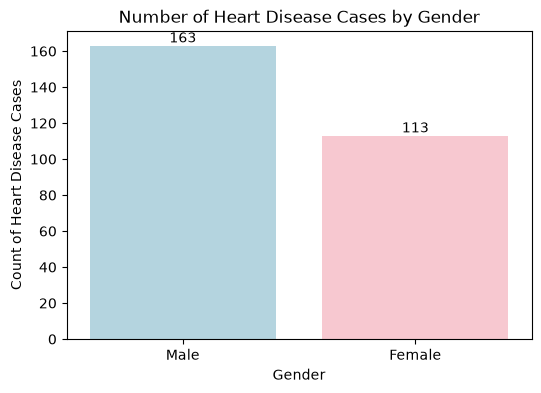

In [16]:
# bar chart: number of males and females who had a heart disease
heart_gender = strokedf[strokedf['heart_disease'] == 1]
plt.figure(figsize=(6,4))
ax = sns.countplot(x='gender', data=heart_gender, palette=['lightblue','pink'])
ax.set_title('Number of Heart Disease Cases by Gender')
ax.set_xlabel('Gender')
ax.set_ylabel('Count of Heart Disease Cases')
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom')
plt.show()

Woman has less heart disease



not that imbananced but women are more in our data set

# Age Analysis

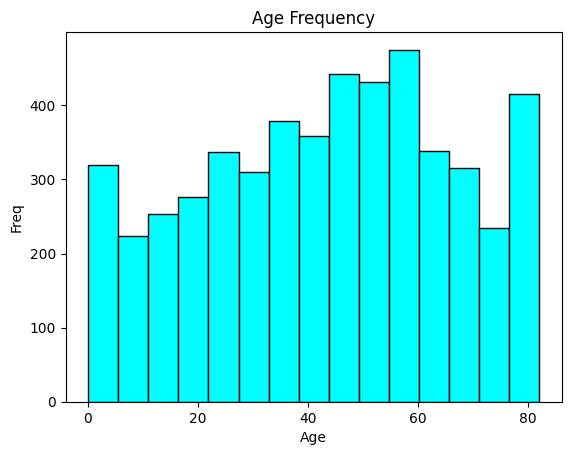

In [111]:
plt.hist(strokedf['age'],bins=15,color='cyan',edgecolor='black',linewidth=1)
plt.title('Age Frequency')
plt.xlabel('Age')
plt.ylabel('Freq')
plt.show()

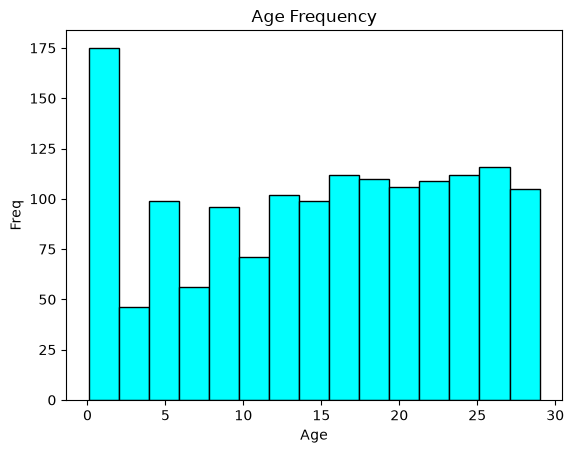

In [18]:
#age distribution less than 30 
plt.hist(strokedf[strokedf['age'] < 30]['age'], bins=15, color='cyan', edgecolor='black', linewidth=1)
plt.title('Age Frequency')
plt.xlabel('Age')
plt.ylabel('Freq')
plt.show()

age outliers detected in high freqency in zeros

# Hypertension Analysis


In [19]:
hyperTension_count=strokedf['hypertension'].value_counts()
hyperTension_percent=strokedf['hypertension'].value_counts(normalize=True)*100
freq_table2=pd.DataFrame({'Count':hyperTension_count,'Percentage %':hyperTension_percent})
freq_table2

,Count,Percentage %
hypertension,,
0,4611,90.252496
1,498,9.747504


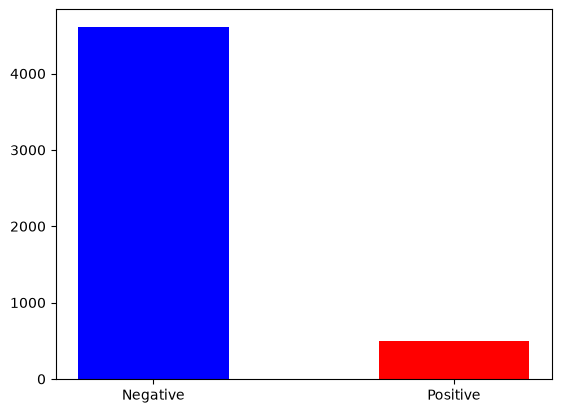

In [20]:
plt.bar(['Negative','Positive'],strokedf['hypertension'].value_counts(),align='center',width=0.5,color=['blue','red'])
plt.show()

Most of the people don't have Hyper Tension


# Heart Disease Analysis

In [114]:
heartDisease_count=strokedf['heart_disease'].value_counts()
heartDisease_percent=strokedf['heart_disease'].value_counts(normalize=True)*100
freq_table6=pd.DataFrame({'Count':heartDisease_count,'Percantage %':heartDisease_percent})
freq_table6

,Count,Percantage %
heart_disease,,
0,4833,94.597769
1,276,5.402231


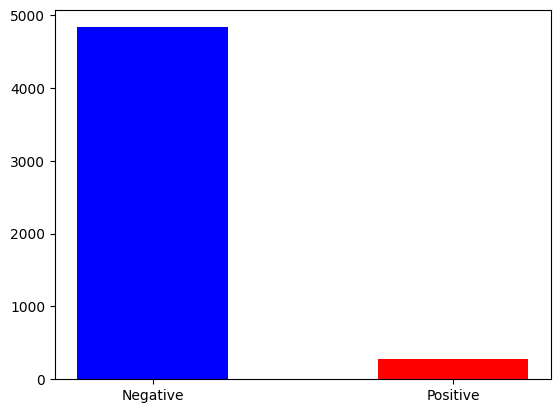

In [115]:
plt.bar(['Negative','Positive'],strokedf['heart_disease'].value_counts(),align='center',width=0.5,color=['blue','red'])
plt.show()

Most of the people don't suffer from Heart Disease


# Marriage Analysis

In [116]:
married_count=strokedf['ever_married'].value_counts()
married_percent=strokedf['ever_married'].value_counts(normalize=True)*100
freq_table3=pd.DataFrame({'Count':married_count,'Percentage %':married_percent})
freq_table3

,Count,Percentage %
ever_married,,
Yes,3353,65.629282
No,1756,34.370718


<Axes: xlabel='ever_married', ylabel='count'>

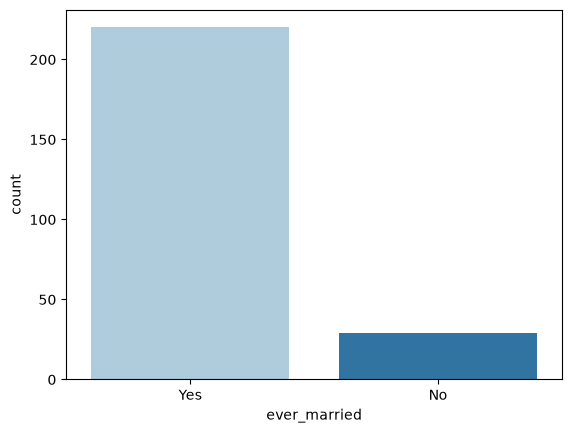

In [27]:
stroke_only = strokedf[strokedf['stroke'] == 1]

sns.countplot(x='ever_married',palette=sns.color_palette("Paired"),data=stroke_only)

Most people are/ was married


# Work Type Analysis


In [118]:
job_count=strokedf['work_type'].value_counts()
job_percent=strokedf['work_type'].value_counts(normalize=True)*100
freq_table4=pd.DataFrame({'Count':job_count,'Percentage %':job_percent})
freq_table4

,Count,Percentage %
work_type,,
Private,2924,57.232335
Self-employed,819,16.030534
children,687,13.446858
Govt_job,657,12.859659
Never_worked,22,0.430613


<Axes: xlabel='work_type', ylabel='count'>

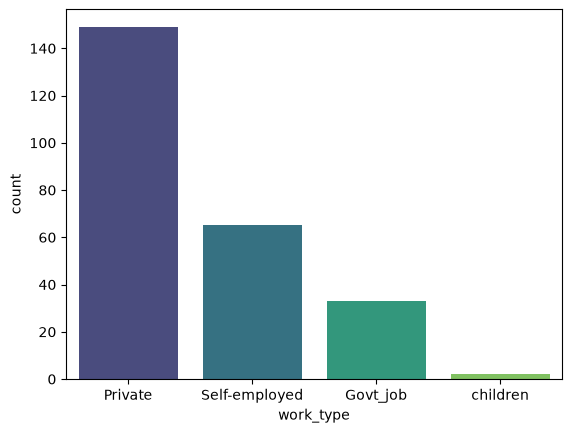

In [26]:
stroke_only = strokedf[strokedf['stroke'] == 1]
sns.countplot(x='work_type',palette='viridis',data=stroke_only)

# Residence Type Analysis

In [120]:
Residence_type_count=strokedf['Residence_type'].value_counts()
Residence_type_percent=strokedf['Residence_type'].value_counts(normalize=True)*100
freq_table5=pd.DataFrame({'Count':Residence_type_count,'Percentage %':Residence_type_percent})
freq_table5

,Count,Percentage %
Residence_type,,
Urban,2596,50.812292
Rural,2513,49.187708


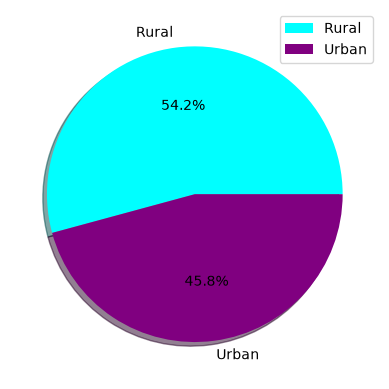

In [28]:
plt.pie(stroke_only['Residence_type'].value_counts(),labels=['Rural','Urban'],colors=['cyan','purple'],autopct='%1.1f%%',shadow=True)
plt.legend()
plt.show()

almost equal

# Average Glucose Level Analysis


In [122]:
strokedf['avg_glucose_level'].describe()


count    5109.000000
mean      100.988838
std        33.214602
min        55.120000
25%        77.240000
50%        91.880000
75%       114.090000
max       169.365000
Name: avg_glucose_level, dtype: float64

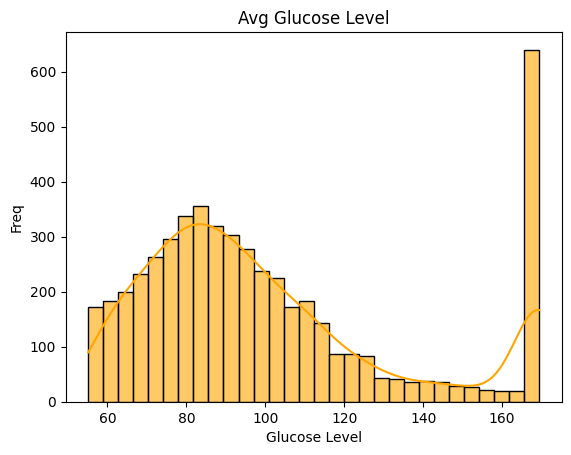

In [123]:
sns.histplot(strokedf['avg_glucose_level'],bins=30,kde=True,color='orange',edgecolor='black',linewidth=1,alpha=0.6)
plt.title('Avg Glucose Level')
plt.xlabel('Glucose Level')
plt.ylabel('Freq')
plt.show()

# BMI analysis

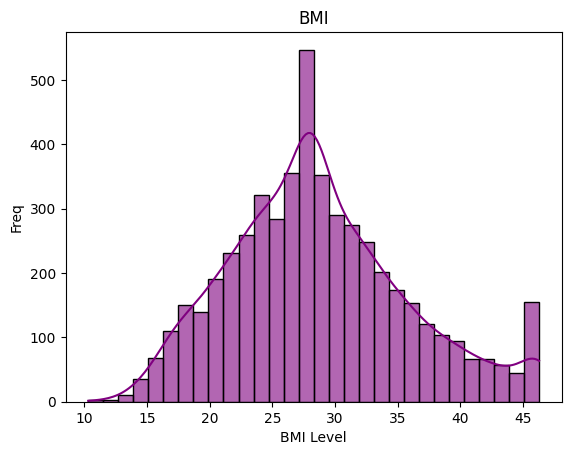

In [124]:
sns.histplot(strokedf['bmi'],bins=30,kde=True,color='purple',edgecolor='black',linewidth=1,alpha=0.6)
plt.title('BMI')
plt.xlabel('BMI Level')
plt.ylabel('Freq')
plt.show()

Underweight: BMI less than 18.5

Normal weight: BMI 18.5 to 24.9

Overweight: BMI 25 to 29.9

Obesity: BMI 30 or higher

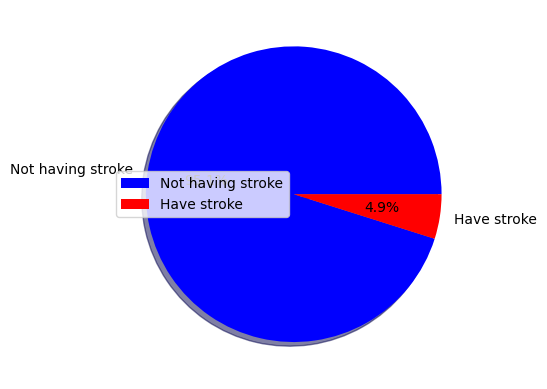

In [125]:
plt.pie(strokedf['stroke'].value_counts(),labels=['Not having stroke','Have stroke'],colors=['blue','red'],autopct='%1.1f%%',shadow=True)
plt.legend()
plt.show()

Most of the people don't suffer a stroke.

# Bivariate Analysis

Text(0.5, 1.0, 'Age vs Stroke')

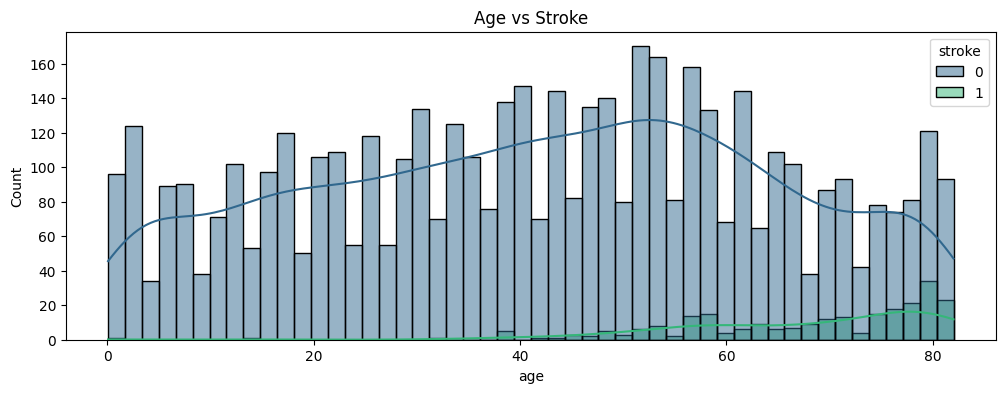

In [126]:
plt.figure(figsize=(12, 4))
pl = sns.histplot(x='age', data=strokedf, hue='stroke', bins=50, kde=True, palette='viridis')
pl.set_title('Age vs Stroke')

* Stroke incidents "gray" increase  after age 40
* The highest concentration of stroke cases appears in the 60-80 age range
* Very few stroke cases are reported in patients under 40
* The overall distribution shows age is a significant risk factor for strokes

Text(0.5, 1.0, 'Average Glucose Level vs Stroke')

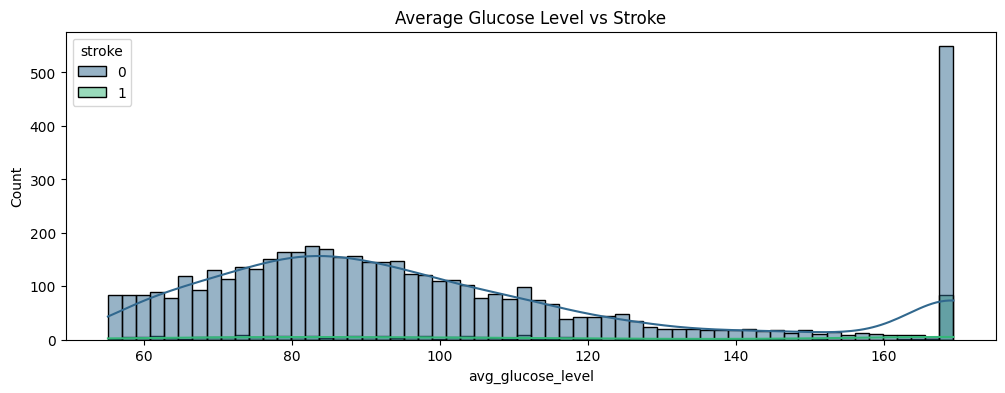

In [127]:
plt.figure(figsize=(12,4))
pl = sns.histplot(x='avg_glucose_level', data=strokedf, hue='stroke', bins=60 , kde=True, palette='viridis')
pl.set_title('Average Glucose Level vs Stroke')

* stroke not affacted by Glucose level as people have Stroke in all glucose levels 

Text(0.5, 1.0, 'Stroke vs BMI')

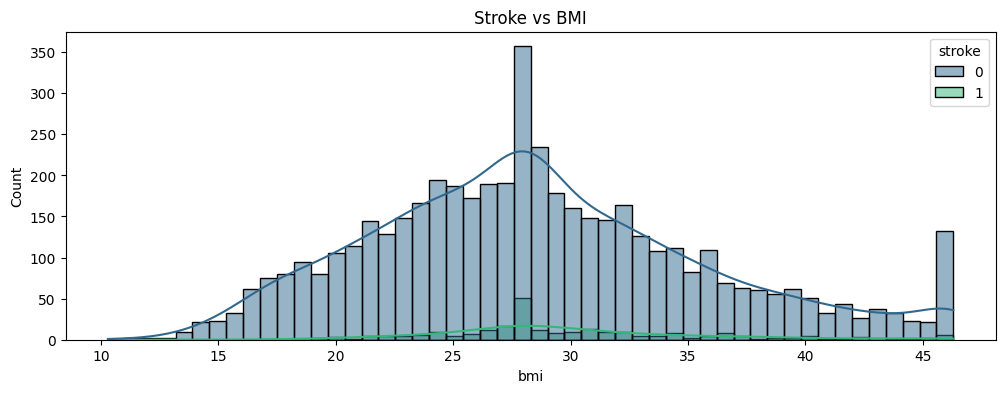

In [128]:
plt.figure(figsize=(12,4))
pl = sns.histplot(x='bmi', data=strokedf, hue='stroke', bins=50, kde=True, palette='viridis')
pl.set_title('Stroke vs BMI')

* The majority of the population has BMI between 20-40
* Stroke cases  appear more frequently in the overweight and obese ranges (BMI > 25)
* The data suggests being overweight or obese may increase stroke risk
* though the relationship appears less significant than with age or glucose levels

### Smoke state vs stroke 

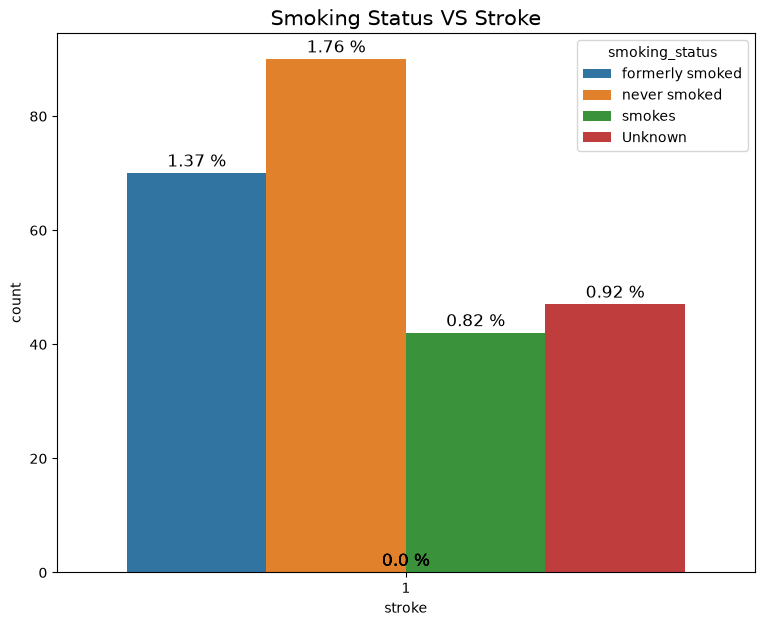

In [25]:
countplt, ax = plt.subplots(figsize = (9,7))
stroke_only = strokedf[strokedf['stroke'] == 1]

ax = sns.countplot(
    data=stroke_only, 
    x='stroke', 
    hue='smoking_status', 
)
ax.set_title("Smoking Status VS Stroke",fontsize = 15)
for p in ax.patches:
        ax.annotate(f'{round(p.get_height()/len(strokedf)*100,2)} %', xy=(p.get_x() + p.get_width() / 2,  
            p.get_height()), ha='center',  va='center',size=12, xytext=(0, 8),textcoords='offset points')
plt.show()

* The highest majority of "non-stroke" cases are among people who never smoked (35.27%) but "Surprise" current smokers have a slightly lower "stroke rate" (0.82%) compared to those who never smoked (1.76%) or formerly smoked (1.37%) 

* for me I think "this could be influenced by other factors like age distribution or sample size limitations" not logic

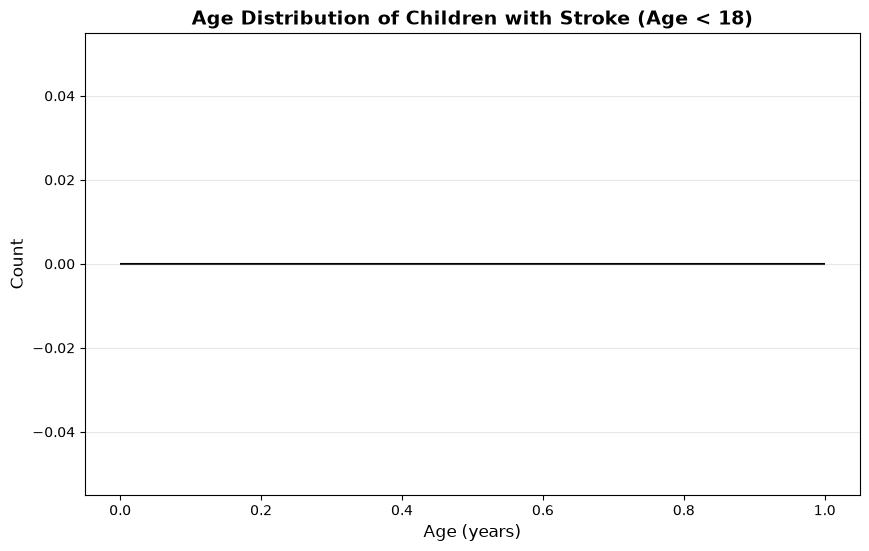

Total children with stroke: 0

Age statistics for children with stroke:
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: age, dtype: float64


In [73]:
# Filter for children (age < 18) who had a stroke
children_stroke = strokedf[(strokedf['age'] < 18) & (strokedf['stroke'] == 1)]

# Create a histogram showing age distribution of children with stroke
plt.figure(figsize=(10, 6))
plt.hist(children_stroke['age'], bins=15, color='coral', edgecolor='black', linewidth=1.5)
plt.title('Age Distribution of Children with Stroke (Age < 18)', fontsize=14, fontweight='bold')
plt.xlabel('Age (years)', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.show()

print(f"Total children with stroke: {len(children_stroke)}")
print(f"\nAge statistics for children with stroke:")
print(children_stroke['age'].describe())


these results shows that data may be mistakly collect data for childern because they all do not have stroke and this may be a noise for our analysis so we can drop rows with age less than 18

In [130]:
print("Unique values for 'work_type':", strokedf['work_type'].unique())
print("Unique values for 'gender':", strokedf['gender'].unique())
print("Unique values for 'Residence_type':", strokedf['Residence_type'].unique())
print("Unique values for 'ever_married':", strokedf['ever_married'].unique())
print("Unique values for 'smoking_status':", strokedf['smoking_status'].unique())


Unique values for 'work_type': ['Private' 'Self-employed' 'Govt_job' 'children' 'Never_worked']
Unique values for 'gender': ['Male' 'Female']
Unique values for 'Residence_type': ['Urban' 'Rural']
Unique values for 'ever_married': ['Yes' 'No']
Unique values for 'smoking_status': ['formerly smoked' 'never smoked' 'smokes' 'Unknown']


 OneHotEncode to encode the rest categorical columns: work_type ,smoking_status

 because it creates separate binary columns for each category (without implying any ranking or order). avoid any inadvanced problems with algorithms

## After cleaning and encoding data , let's see relations 

In [38]:
clean=pd.read_csv("../data/cleaned.csv")
clean.head()

,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Male,ever_married_Yes,work_type_Self-employed,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,stroke
0,31,0,0,4,23,1,0,1,0,0,0,0
1,40,0,0,4,28,1,1,1,0,1,0,0
2,79,1,0,4,19,0,1,1,0,1,0,0
3,75,0,0,4,27,0,1,0,0,1,0,0
4,79,1,0,4,28,0,1,1,0,1,0,0


# Feature Engineering

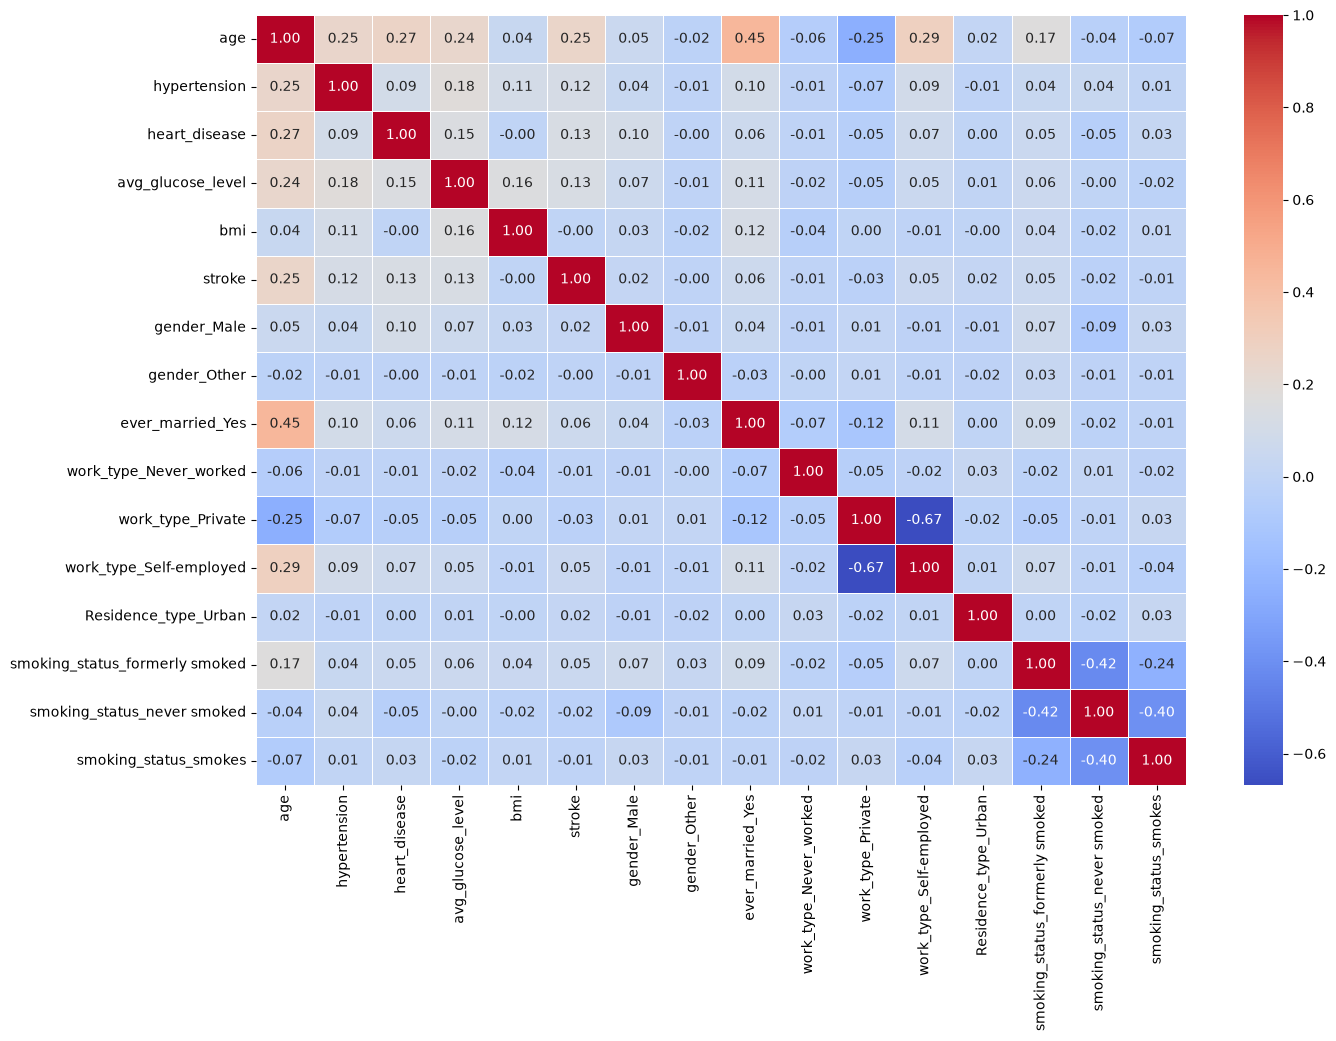

In [90]:
clean=pd.read_csv("../data/cleaned.csv")
plt.figure(figsize=(15, 10))
sns.heatmap(clean.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.show()

##### insights: 
- gender_Other: Its correlation with stroke is exactly -0.00. This category likely has too few samples, providing no predictive value.
- work_type_Never_worked: Correlation with stroke is near zero (-0.01). It adds unnecessary noise to the dataset.
- Residence_type_Urban: Correlation with stroke is very weak (0.02). Whether a patient lives in a rural or urban area does not impact stroke risk in this data.
- Primary Medical Indicators: Keep age (0.25), avg_glucose_level (0.13), heart_disease (0.13), and hypertension (0.12). These are your most powerful features.
- Social/Behavioral Factors: Keep ever_married_Yes (0.06), work_type_Self-employed (0.05), and smoking_status_formerly smoked (0.05).
- Keeping bmi (Important Exception): Even though bmi shows a -0.00 linear correlation with stroke, do not drop it. Body Mass Index often has a non-linear relationship with health risks. Tree-based models (like Random Forest) can still find complex patterns using it.
- Age is the Strongest Predictor: At 0.25, age has the highest direct correlation with stroke.
- The "Age Confounder" Effect: Age is strongly correlated with being married (0.45) and being self-employed (0.29). This suggests that marriage and self-employment appear correlated with stroke mostly because older people are more likely to be married and self-employed.
- High Multicollinearity: There is a strong negative correlation (-0.67) between work_type_Private and work_type_Self-employed.
- The Smoking Paradox: formerly smoked has a higher correlation with stroke (0.05) than currently smoking (0.01). This often happens because people quit smoking after they begin developing health issues or getting older.

## dropping uncorreleted columns 

In [91]:
columns_to_keep = [
    'age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi',
    'gender_Male', 'ever_married_Yes', 'work_type_Self-employed',
    'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes',
    'stroke'  
]

strokedf_filtered = clean[columns_to_keep]
strokedf_filtered.to_csv("../data/cleaned.csv", index=False)

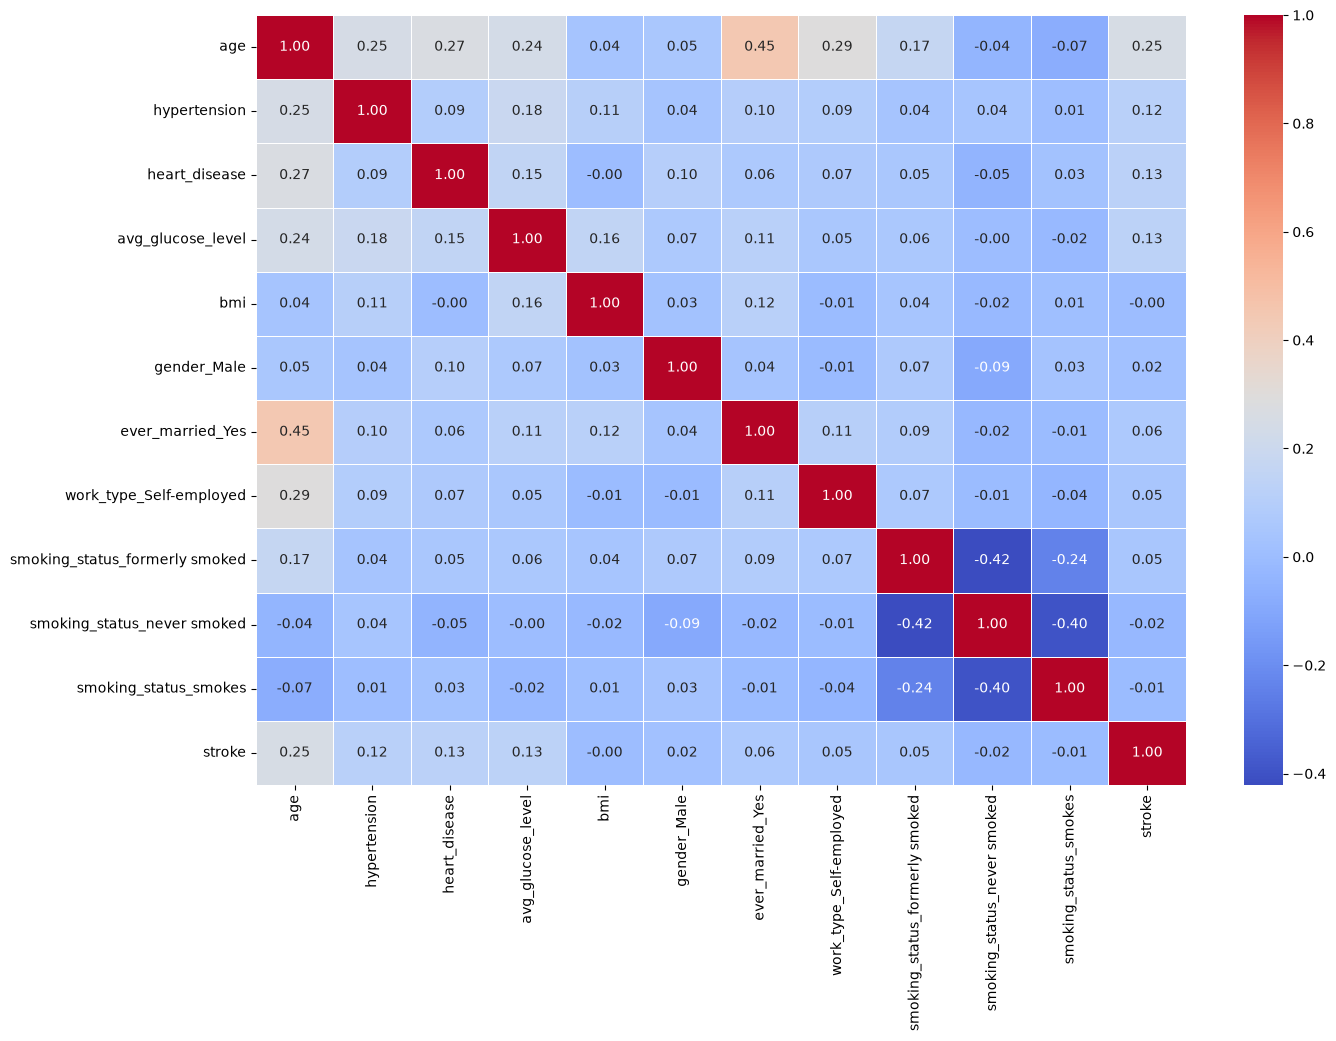

In [92]:
clean=pd.read_csv("../data/cleaned.csv")
plt.figure(figsize=(15, 10))
sns.heatmap(clean.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.show()

# creating a health risk factor to see the corrilation with stroke 

In [93]:
clean['health_factor'] = (
    clean['hypertension'] + 
    clean['heart_disease'] + 
    (clean['avg_glucose_level'] > 140).astype(int) 
)

pd.DataFrame(clean).to_csv("../data/cleaned.csv", index=False)

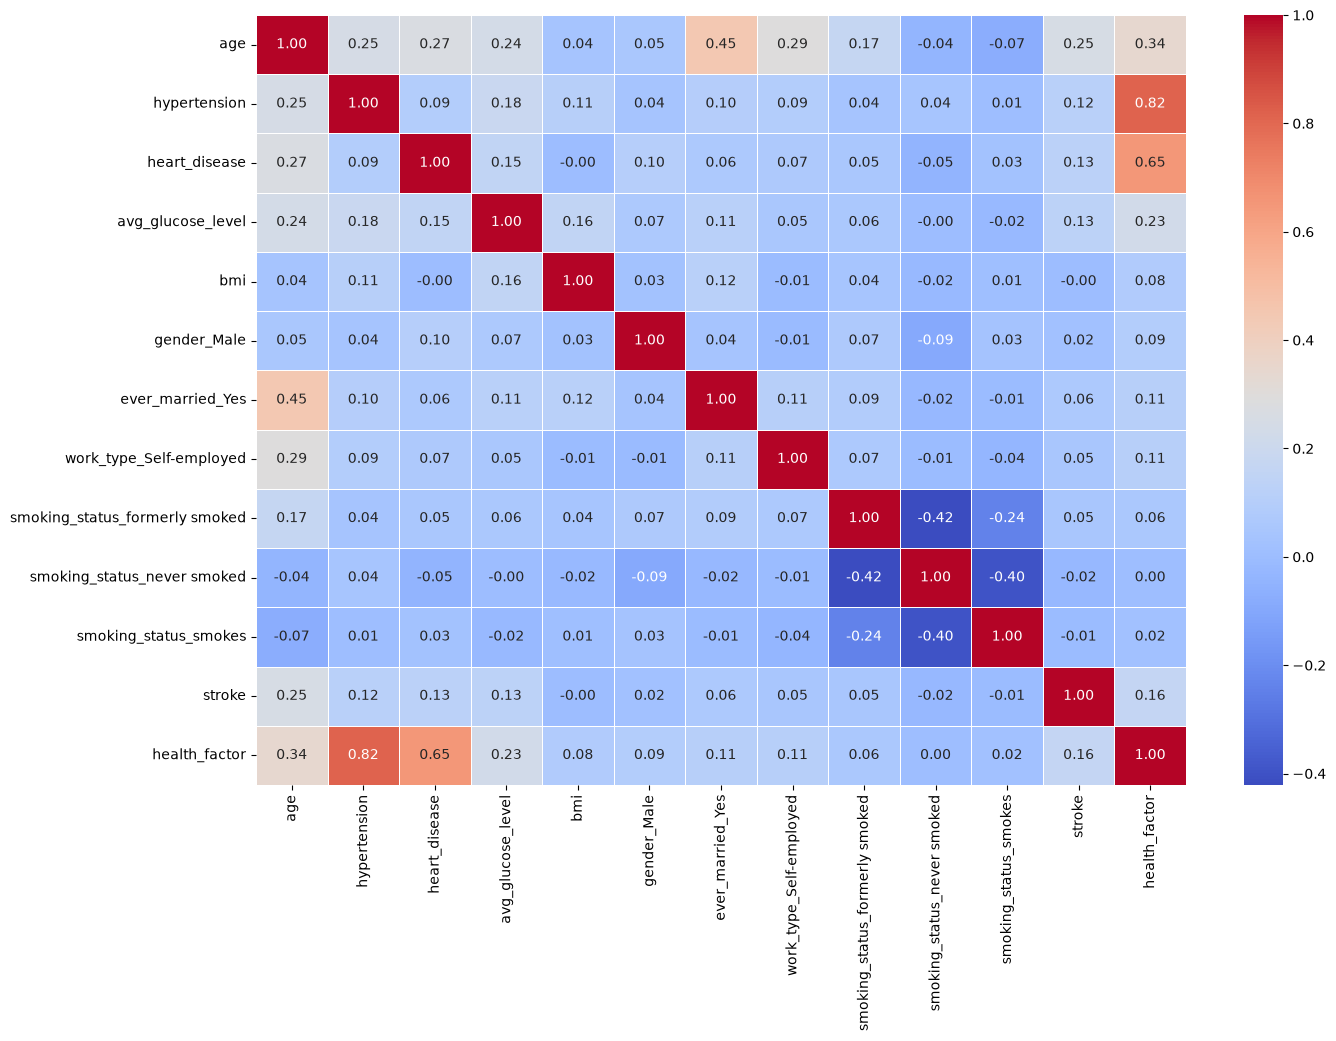

In [94]:
plt.figure(figsize=(15, 10))
sns.heatmap(clean.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.show()

### insights : 
- in previous corr the heart disease was 0.12 and hypertention was 0.12 and ave gluocouse level was 0.13 and health factor increased to 0.16 so it is a good feature to keep 